# 05 - External validation and unseen-disease test
Two questions a reviewer will ask, answered on a **second, independent OCT dataset** - without retraining anything:

1. **Does it generalise?** Accuracy on external scans of the four classes the model knows (CNV, DME, DRUSEN, NORMAL), compared with the internal test set. Different scanner or hospital = a drop in accuracy is expected; the size of the drop is the finding.
2. **Does the uncertainty score notice what it has never seen?** The external set also contains diseases that are *not* in our label set (OCT-C8: AMD, CSR, DR, MH). A useful uncertainty score should be higher on them. Evidential vs softmax is compared here, where the evidential claim is usually made.

**Default dataset: Retinal OCT-C8** (Kaggle `obulisainaren/retinal-oct-c8`, 24,000 scans, 8 classes: AMD, CNV, CSR, DME, DR, DRUSEN, MH, NORMAL, 3,000 each; train/val/test folders).
Download it and unzip it anywhere; point `EXT_ROOT` at the folder. Any other dataset works too: put scans in class folders and edit `CLASS_MAP`.

**Overlap guard.** Public OCT sets sometimes share images (OCT-C8 has image sizes similar to the set we trained on). Before anything is evaluated, every external file is compared with the training data by file hash and by a 256-bit image hash.
Overlapping scans are removed, and the counts are reported - an "external" set that overlaps is not external.

Needs PyTorch for sections 5+; the checks before that need only numpy and Pillow.

## 1. Settings

In [10]:
import re, io, csv, json, time, random, hashlib, collections
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw):
        return x

# ---------------- settings ----------------
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")     # our clean dataset (notebook 01)
EXT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_C8")        # external dataset (any folder layout; class = parent folder name)
RUNS_DIR = Path("outputs") / "runs"                                    # trained runs (notebook 03)
OUT_DIR = Path("outputs") / "external"

CLASS_MAP = {"CNV": "CNV", "DME": "DME", "DRUSEN": "DRUSEN", "NORMAL": "NORMAL"}   # external folder -> our class
OOD_CLASSES = ["AMD", "CSR", "DR", "MH"]     # external classes our model has no label for (set [] to skip section 7)
RUN_NAMES = None                              # e.g. ["cnn_softmax_s42", "ms_evidential_s42"]; None = lowest seed of every variant
MAX_PER_CLASS = None                          # e.g. 1000 for a quick test run
NEAR_BITS = 7                                 # near-duplicate = 256-bit hashes differing in <= 7 bits
SEED = 42
WORKERS = 8
# -------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)
EXTS = {".jpeg", ".jpg", ".png"}
RES = getattr(Image, "Resampling", Image)
bitcount = int.bit_count if hasattr(int, "bit_count") else (lambda x: bin(x).count("1"))
random.seed(SEED); np.random.seed(SEED)

if not EXT_ROOT.is_dir():
    raise FileNotFoundError(
        f"External dataset not found at {EXT_ROOT}.\n"
        "Download 'Retinal OCT-C8' from https://www.kaggle.com/datasets/obulisainaren/retinal-oct-c8 (button 'Download'), "
        "unzip it, and set EXT_ROOT to the unzipped folder.")
if not (OUT_ROOT / "manifest.csv").exists():
    raise FileNotFoundError(f"manifest.csv not found in {OUT_ROOT}. Run notebook 01 first.")
print("External dataset:", EXT_ROOT)

External dataset: C:\Users\User\Desktop\retinaldataset\OCT_C8


## 2. Inventory and overlap check
Every external file gets: a file hash and a 256-bit difference hash (computed exactly as in notebook 01), size, and a group - `id` (a class we know), `ood` (a class we don't), or `ignored`.
The hashes are compared with **all** images of our dataset.

In [11]:
def hash_record(path):
    rec = dict(path=str(path), ext_cls=path.parent.name.upper(), ok=1, w=0, h=0, md5="", dhash="")
    try:
        data = path.read_bytes()
        rec["md5"] = hashlib.md5(data).hexdigest()
        im = Image.open(io.BytesIO(data))
        im.load()
        rec["w"], rec["h"] = im.size
        small = np.asarray(im.convert("L").resize((17, 16), RES.BILINEAR), dtype=np.float32)
        rec["dhash"] = np.packbits((small[:, 1:] > small[:, :-1]).flatten()).tobytes().hex()
    except Exception:
        rec["ok"] = 0
    return rec

files = sorted(p for p in EXT_ROOT.rglob("*") if p.suffix.lower() in EXTS)
print(f"{len(files):,} image files found under {EXT_ROOT}")
t0 = time.time()
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    E = list(tqdm(ex.map(hash_record, files), total=len(files), desc="hashing external"))
print(f"hashed in {time.time() - t0:.0f}s")

ood_set = {c.upper() for c in OOD_CLASSES}
cmap = {k.upper(): v for k, v in CLASS_MAP.items()}
for r in E:
    r["group"] = "id" if r["ext_cls"] in cmap else ("ood" if r["ext_cls"] in ood_set else "ignored")
    r["cls"] = cmap.get(r["ext_cls"], r["ext_cls"])

# compare with our dataset (hashes of the original files are in manifest.csv)
with open(OUT_ROOT / "manifest.csv", newline="", encoding="utf-8") as f:
    M = list(csv.DictReader(f))
md5_set = {r["md5"] for r in M}
mf_int = [int(r["dhash"], 16) for r in M]
chunk_index = collections.defaultdict(list)
for j, r in enumerate(M):
    for c in range(8):
        chunk_index[(c, r["dhash"][c * 8:(c + 1) * 8])].append(j)

def near_match(h):
    hi, cand = int(h, 16), set()
    for c in range(8):
        b = chunk_index.get((c, h[c * 8:(c + 1) * 8]), [])
        if len(b) <= 400:
            cand.update(b)
    return any(bitcount(hi ^ mf_int[j]) <= NEAR_BITS for j in cand)

for r in tqdm(E, desc="comparing with our dataset"):
    r["exact"] = bool(r["ok"] and r["md5"] in md5_set)
    r["near"] = bool(r["ok"] and not r["exact"] and near_match(r["dhash"]))
    r["keep"] = bool(r["ok"] and r["group"] != "ignored" and not r["exact"] and not r["near"])

print("\n" + "external class".ljust(16) + "group".ljust(9) + "files".rjust(7) + "exact copy".rjust(12) + "near copy".rjust(11) + "kept".rjust(7))
for c in sorted({r["ext_cls"] for r in E}):
    rs = [r for r in E if r["ext_cls"] == c]
    print(c.ljust(16) + rs[0]["group"].ljust(9) + f"{len(rs):7,d}{sum(r['exact'] for r in rs):12,d}{sum(r['near'] for r in rs):11,d}{sum(r['keep'] for r in rs):7,d}")
n_ov = sum(r["exact"] or r["near"] for r in E)
print(f"\nOverlap with our dataset: {n_ov:,} of {len(E):,} external files ({n_ov / max(len(E), 1) * 100:.1f}%) - removed from everything below.")
if n_ov > 0.3 * len(E):
    print("WARNING: more than 30% of this dataset is already in our data - it is only partly external. Report the overlap in the paper.")
with open(OUT_DIR / "external_overlap.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["path", "ext_class", "exact_copy", "near_copy"])
    for r in E:
        if r["exact"] or r["near"]:
            w.writerow([r["path"], r["ext_cls"], int(r["exact"]), int(r["near"])])

24,000 image files found under C:\Users\User\Desktop\retinaldataset\OCT_C8


hashing external: 100%|██████████| 24000/24000 [00:28<00:00, 832.54it/s]


hashed in 29s


comparing with our dataset: 100%|██████████| 24000/24000 [00:00<00:00, 213716.14it/s]



external class  group      files  exact copy  near copy   kept
AMD             ood        3,000           0          0  3,000
CNV             id         3,000       2,985          0     15
CSR             ood        3,000           0          0  3,000
DME             id         3,000       2,992          0      8
DR              ood        3,000           0          0  3,000
DRUSEN          id         3,000       2,928          0     72
MH              ood        3,000           0          0  3,000
NORMAL          id         3,000       2,998          0      2

Overlap with our dataset: 11,903 of 24,000 external files (49.6%) - removed from everything below.


## 3. Standardise the external scans
Exactly the same steps as notebook 01 (grayscale, same resize mode and size, taken from `stats.json`), so the model sees the external scans like it saw its own data.

In [12]:
STATS = json.load(open(OUT_ROOT / "stats.json")) if (OUT_ROOT / "stats.json").exists() else {}
OUT_SIZE = STATS.get("image_size", 256)
RESIZE_MODE = STATS.get("resize_mode", "squash")

def standardise(g):
    w, h, S = g.size[0], g.size[1], OUT_SIZE
    if RESIZE_MODE == "squash":
        return g.resize((S, S), RES.LANCZOS)
    if RESIZE_MODE == "center_crop":
        side = min(w, h)
        left, top = (w - side) // 2, (h - side) // 2
        return g.crop((left, top, left + side, top + side)).resize((S, S), RES.LANCZOS)
    scale = S / max(w, h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    canvas = Image.new("L", (S, S), 0)
    canvas.paste(g.resize((nw, nh), RES.LANCZOS), ((S - nw) // 2, (S - nh) // 2))
    return canvas

rng = random.Random(SEED)
kept = [r for r in E if r["keep"]]
if MAX_PER_CLASS:
    by_c = collections.defaultdict(list)
    for r in kept:
        by_c[r["ext_cls"]].append(r)
    kept = [r for c in sorted(by_c) for r in rng.sample(by_c[c], min(MAX_PER_CLASS, len(by_c[c])))]
print(f"{len(kept):,} external scans to evaluate | resize mode '{RESIZE_MODE}', {OUT_SIZE}px (as in notebook 01)")

def prep(i):
    g = Image.open(kept[i]["path"])
    g.load()
    return i, np.asarray(standardise(g.convert("L")), dtype=np.uint8)

X = np.zeros((len(kept), OUT_SIZE, OUT_SIZE), dtype=np.uint8)
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    for i, a in tqdm(ex.map(prep, range(len(kept))), total=len(kept), desc="standardising"):
        X[i] = a
GROUP = np.array([r["group"] for r in kept])
EXT_CLS = np.array([r["ext_cls"] for r in kept])
OUR_CLS = np.array([r["cls"] for r in kept])
print("array", X.shape, X.dtype, f"| {X.nbytes / 1e9:.2f} GB in memory | in-distribution {int((GROUP == 'id').sum()):,} | unseen classes {int((GROUP == 'ood').sum()):,}")

12,097 external scans to evaluate | resize mode 'squash', 256px (as in notebook 01)


standardising: 100%|██████████| 12097/12097 [00:09<00:00, 1212.57it/s]

array (12097, 256, 256) uint8 | 0.79 GB in memory | in-distribution 97 | unseen classes 12,000


## 4. Metric helpers (numpy)

In [13]:
def confusion(y, p, k):
    return np.bincount(y * k + p, minlength=k * k).reshape(k, k)

def prf(cm):
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(cm.sum(1), 1)
    return prec, rec, 2 * prec * rec / np.maximum(prec + rec, 1e-12)

def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    ok = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

def auroc(pos, neg):
    # P(score of a positive > score of a negative), ties count half
    v = np.concatenate([pos, neg])
    _, inv, cnt = np.unique(v, return_inverse=True, return_counts=True)
    r = (np.cumsum(cnt) - (cnt - 1) / 2.0)[inv]
    n1, n0 = len(pos), len(neg)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def acc_at_coverage(y, pred, unc, cov):
    order = np.argsort(unc, kind="stable")
    keep_ = order[:max(1, int(round(cov * len(y))))]
    return float((y[keep_] == pred[keep_]).mean())

def bootstrap_ci(y, pred, k, n_boot=1000, seed=0):
    rg = np.random.default_rng(seed)
    n = len(y)
    accs, f1s = [], []
    for _ in range(n_boot):
        idx = rg.integers(0, n, n)
        accs.append((y[idx] == pred[idx]).mean())
        f1s.append(prf(confusion(y[idx], pred[idx], k))[2].mean())
    return [float(v) for v in np.percentile(accs, [2.5, 97.5])], [float(v) for v in np.percentile(f1s, [2.5, 97.5])]

def fpr_at_95_id(id_scores, ood_scores):
    # threshold keeps 95% of in-distribution scans; FPR = share of unseen-class scans that still pass as 'known'
    thr = np.percentile(id_scores, 95)
    return float((ood_scores <= thr).mean())

def entropy(probs):
    return -(probs * np.log(np.clip(probs, 1e-12, 1))).sum(1)

## 5. Load the trained runs

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_tiny

class OCTNet(nn.Module):          # identical to notebook 03
    def __init__(self, model, num_classes, dim=256, depth=2, heads=4, dropout=0.1):
        super().__init__()
        self.multiscale = model == "ms"
        self.features = convnext_tiny(weights=None).features
        if self.multiscale:
            self.proj = nn.ModuleList([nn.Sequential(nn.Conv2d(c, dim, 1), nn.AdaptiveAvgPool2d(7)) for c in (192, 384, 768)])
            self.cls = nn.Parameter(torch.zeros(1, 1, dim))
            self.pos = nn.Parameter(torch.zeros(1, 3 * 49 + 1, dim))
            self.tok_norm = nn.LayerNorm(dim)
            layer = nn.TransformerEncoderLayer(dim, heads, dim_feedforward=dim * 2, dropout=dropout,
                                               activation="gelu", batch_first=True, norm_first=True)
            self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
            self.out_norm = nn.LayerNorm(dim)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dim, num_classes))
        else:
            self.pool_norm = nn.LayerNorm(768)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(768, num_classes))

    def forward(self, x):
        f = self.features
        x = f[2](f[1](f[0](x)))
        f2 = f[3](x)
        f3 = f[5](f[4](f2))
        f4 = f[7](f[6](f3))
        if not self.multiscale:
            return self.head(self.pool_norm(f4.mean((2, 3))))
        toks = [p(t).flatten(2).transpose(1, 2) for p, t in zip(self.proj, (f2, f3, f4))]
        t = self.tok_norm(torch.cat(toks, dim=1))
        t = torch.cat([self.cls.expand(t.size(0), -1, -1), t], dim=1) + self.pos
        return self.head(self.out_norm(self.encoder(t))[:, 0])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
PIPE = json.load(open(OUT_ROOT / "pipeline.json")) if (OUT_ROOT / "pipeline.json").exists() else {}
IMG = PIPE.get("net_input_size", 224)
MEAN, STD = PIPE.get("mean", [0.485, 0.456, 0.406]), PIPE.get("std", [0.229, 0.224, 0.225])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ArrayDS(torch.utils.data.Dataset):
    def __init__(self, arr):
        self.arr = arr
    def __len__(self):
        return len(self.arr)
    def __getitem__(self, i):
        return eval_tf(Image.fromarray(self.arr[i]).convert("RGB")), 0

loader = torch.utils.data.DataLoader(ArrayDS(X), batch_size=128, shuffle=False, num_workers=0)

all_runs = {}
for d in sorted(RUNS_DIR.glob("*_s*")):
    m = re.match(r"^(cnn|ms)_(softmax|evidential)_s(\d+)$", d.name)
    if m and (d / "best.pt").exists() and (d / "metrics.json").exists():
        all_runs[d.name] = dict(dir=d, variant=f"{m[1]}_{m[2]}", seed=int(m[3]))
if RUN_NAMES:
    chosen = {n: all_runs[n] for n in RUN_NAMES}
else:
    best_seed = {}
    for n, r in all_runs.items():
        if r["variant"] not in best_seed or r["seed"] < all_runs[best_seed[r["variant"]]]["seed"]:
            best_seed[r["variant"]] = n
    chosen = {n: all_runs[n] for n in best_seed.values()}
if not chosen:
    raise FileNotFoundError(f"No finished runs in {RUNS_DIR}. Run notebook 03 first.")
print("Runs to evaluate:", ", ".join(chosen), "| device:", DEVICE)

Runs to evaluate: cnn_softmax_s42 | device: cuda


## 6. Predict on the external scans
For each run: class probabilities and the run's own uncertainty score (evidential `u = K / S`, softmax `1 - max probability`).
Two further scores are computed for every model so they can be compared fairly: `1 - max probability` and predictive entropy.

In [15]:
@torch.no_grad()
def predict(net, evidential):
    net.eval()
    probs, unc = [], []
    for x, _ in tqdm(loader, desc="predicting", leave=False):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = net(x.to(DEVICE, non_blocking=True))
        logits = logits.float()
        if evidential:
            alpha = F.softplus(logits) + 1.0
            S = alpha.sum(1, keepdim=True)
            p, u = alpha / S, logits.size(1) / S.squeeze(1)
        else:
            p = F.softmax(logits, 1)
            u = 1.0 - p.max(1).values
        probs.append(p.cpu()); unc.append(u.cpu())
    return torch.cat(probs).numpy(), torch.cat(unc).numpy()

PRED = {}
for name, r in chosen.items():
    ck = torch.load(r["dir"] / "best.pt", map_location=DEVICE, weights_only=False)
    cfg = ck["cfg"]
    net = OCTNet(cfg["model"], len(ck["classes"]), cfg.get("dim", 256), cfg.get("depth", 2), cfg.get("heads", 4)).to(DEVICE)
    net.load_state_dict(ck["model"])
    probs, unc = predict(net, cfg["head"] == "evidential")
    PRED[name] = dict(probs=probs, unc=unc, classes=list(ck["classes"]), metrics=json.load(open(r["dir"] / "metrics.json")),
                      internal=np.load(r["dir"] / "test_outputs.npz"))
    del net
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"  {name}: done ({len(probs):,} scans)")
CLASSES = next(iter(PRED.values()))["classes"]
K = len(CLASSES)

  cnn_softmax_s42: done (12,097 scans)


## 7. Result 1 - generalisation to the external dataset
In-distribution external scans only (CNV, DME, DRUSEN, NORMAL). Compared with the internal test set from notebook 03.

In [16]:
id_mask = GROUP == "id"
y_id = np.array([CLASSES.index(c) for c in OUR_CLS[id_mask]])
print(f"External in-distribution scans: {id_mask.sum():,} | per class: " + ", ".join(f"{c} {int((OUR_CLS[id_mask] == c).sum()):,}" for c in CLASSES))

ID_RES = {}
for name, P in PRED.items():
    probs, unc = P["probs"][id_mask], P["unc"][id_mask]
    pred = probs.argmax(1)
    cm = confusion(y_id, pred, K)
    prec, rec, f1 = prf(cm)
    cor = pred == y_id
    a_ci, f_ci = bootstrap_ci(y_id, pred, K)
    ID_RES[name] = dict(acc=float(cor.mean()), macro_f1=float(f1.mean()), acc_ci=a_ci, f1_ci=f_ci, ece=ece_score(probs, y_id),
                        auroc=auroc(unc[~cor], unc[cor]) if (~cor).any() and cor.any() else None,
                        acc_at_90=acc_at_coverage(y_id, pred, unc, 0.9), errors=int((~cor).sum()), cm=cm.tolist(),
                        per_class={c: float(f1[i]) for i, c in enumerate(CLASSES)},
                        internal_acc=P["metrics"]["test"]["acc"], internal_f1=P["metrics"]["test"]["macro_f1"])

print("\n" + "run".ljust(22) + "ext acc (95% CI)".ljust(26) + "ext macro-F1".rjust(13) + "internal acc".rjust(14) + "drop".rjust(9) + "ECE".rjust(8) + "AUROC".rjust(8) + "acc@90%".rjust(9))
for name, r in ID_RES.items():
    print(name.ljust(22) + f"{r['acc'] * 100:.2f}% [{r['acc_ci'][0] * 100:.1f}, {r['acc_ci'][1] * 100:.1f}]".ljust(26) +
          f"{r['macro_f1']:.4f}".rjust(13) + f"{r['internal_acc'] * 100:.2f}%".rjust(14) + f"{(r['acc'] - r['internal_acc']) * 100:+.2f}pp".rjust(9) +
          f"{r['ece']:.3f}".rjust(8) + ("n/a" if r["auroc"] is None else f"{r['auroc']:.3f}").rjust(8) + f"{r['acc_at_90'] * 100:.1f}%".rjust(9))
print("\nPer-class F1 on the external set:")
print("  " + "run".ljust(22) + "".join(c.rjust(9) for c in CLASSES))
for name, r in ID_RES.items():
    print("  " + name.ljust(22) + "".join(f"{r['per_class'][c]:9.3f}" for c in CLASSES))

External in-distribution scans: 97 | per class: CNV 15, DME 8, DRUSEN 72, NORMAL 2

run                   ext acc (95% CI)           ext macro-F1  internal acc     drop     ECE   AUROC  acc@90%
cnn_softmax_s42       58.76% [50.5, 69.1]              0.5209        93.69% -34.93pp   0.382   0.473    58.6%

Per-class F1 on the external set:
  run                         CNV      DME   DRUSEN   NORMAL
  cnn_softmax_s42           0.103    0.824    0.713    0.444


## 8. Result 2 - does the uncertainty score notice unseen diseases?
Unseen-class scans (positives) vs external known-class scans (negatives); both come from the same external dataset, so scanner differences do not confound the comparison.
**AUROC 0.5 = chance, 1.0 = perfect.** FPR@95 = share of unseen-class scans that still look "known" at a threshold that keeps 95% of known scans (lower is better).
Caveat: *not in our label set* is not the same as *unrelated* - AMD and DR overlap clinically with CNV, DRUSEN and DME, so a model that assigns them to a known class is not necessarily wrong. CSR and MH are the cleanest tests.

In [17]:
ood_mask = GROUP == "ood"
OOD_RES = {}
if not ood_mask.any():
    print("No unseen-class scans (OOD_CLASSES empty or missing) - skipped.")
else:
    ood_names = sorted(set(EXT_CLS[ood_mask]))
    print(f"Unseen-class scans: {ood_mask.sum():,} ({', '.join(f'{c} {int((EXT_CLS == c).sum()):,}' for c in ood_names)})\n")
    for name, P in PRED.items():
        sc = {"native": P["unc"], "1-maxprob": 1.0 - P["probs"].max(1), "entropy": entropy(P["probs"])}
        res = {}
        for sname, s in sc.items():
            res[sname] = dict(auroc=auroc(s[ood_mask], s[id_mask]), fpr95=fpr_at_95_id(s[id_mask], s[ood_mask]),
                              per_class={c: auroc(s[EXT_CLS == c], s[id_mask]) for c in ood_names})
        it = P["internal"]
        res["native_vs_internal_test"] = auroc(P["unc"][ood_mask], it["unc"])
        OOD_RES[name] = res

    print("run".ljust(22) + "score".ljust(11) + "AUROC".rjust(7) + "FPR@95".rjust(8) + "   per class AUROC: " + "  ".join(c.rjust(6) for c in ood_names))
    for name, res in OOD_RES.items():
        for sname in ("native", "1-maxprob", "entropy"):
            r = res[sname]
            print(name.ljust(22) + sname.ljust(11) + f"{r['auroc']:7.3f}{r['fpr95']:8.3f}" + " " * 19 + "  ".join(f"{r['per_class'][c]:6.3f}" for c in ood_names))
        print(" " * 22 + f"(native score vs INTERNAL test scans instead: AUROC {res['native_vs_internal_test']:.3f} - inflated by scanner differences)")

    # what do the models call the unseen diseases?
    focus = max(ID_RES, key=lambda n: ID_RES[n]["macro_f1"])
    pred_f = PRED[focus]["probs"].argmax(1)
    print(f"\nWhat {focus} predicts for unseen-class scans (row = unseen class, % of its scans):")
    print("  " + "".join(c.rjust(9) for c in [""] + CLASSES))
    for c in ood_names:
        m = EXT_CLS == c
        print("  " + c.ljust(9) + "".join(f"{(pred_f[m] == k).mean() * 100:8.0f}%" for k in range(K)))

Unseen-class scans: 12,000 (AMD 3,000, CSR 3,000, DR 3,000, MH 3,000)

run                   score        AUROC  FPR@95   per class AUROC:    AMD     CSR      DR      MH
cnn_softmax_s42       native       0.314   0.959                    0.664   0.148   0.231   0.211
cnn_softmax_s42       1-maxprob    0.314   0.959                    0.664   0.148   0.231   0.211
cnn_softmax_s42       entropy      0.316   0.946                    0.676   0.148   0.231   0.211
                      (native score vs INTERNAL test scans instead: AUROC 0.537 - inflated by scanner differences)

What cnn_softmax_s42 predicts for unseen-class scans (row = unseen class, % of its scans):
                 CNV      DME   DRUSEN   NORMAL
  AMD            17%      17%      52%      14%
  CSR            93%       2%       0%       6%
  DR              9%      87%       0%       4%
  MH              8%      87%       0%       4%


## 9. Plots

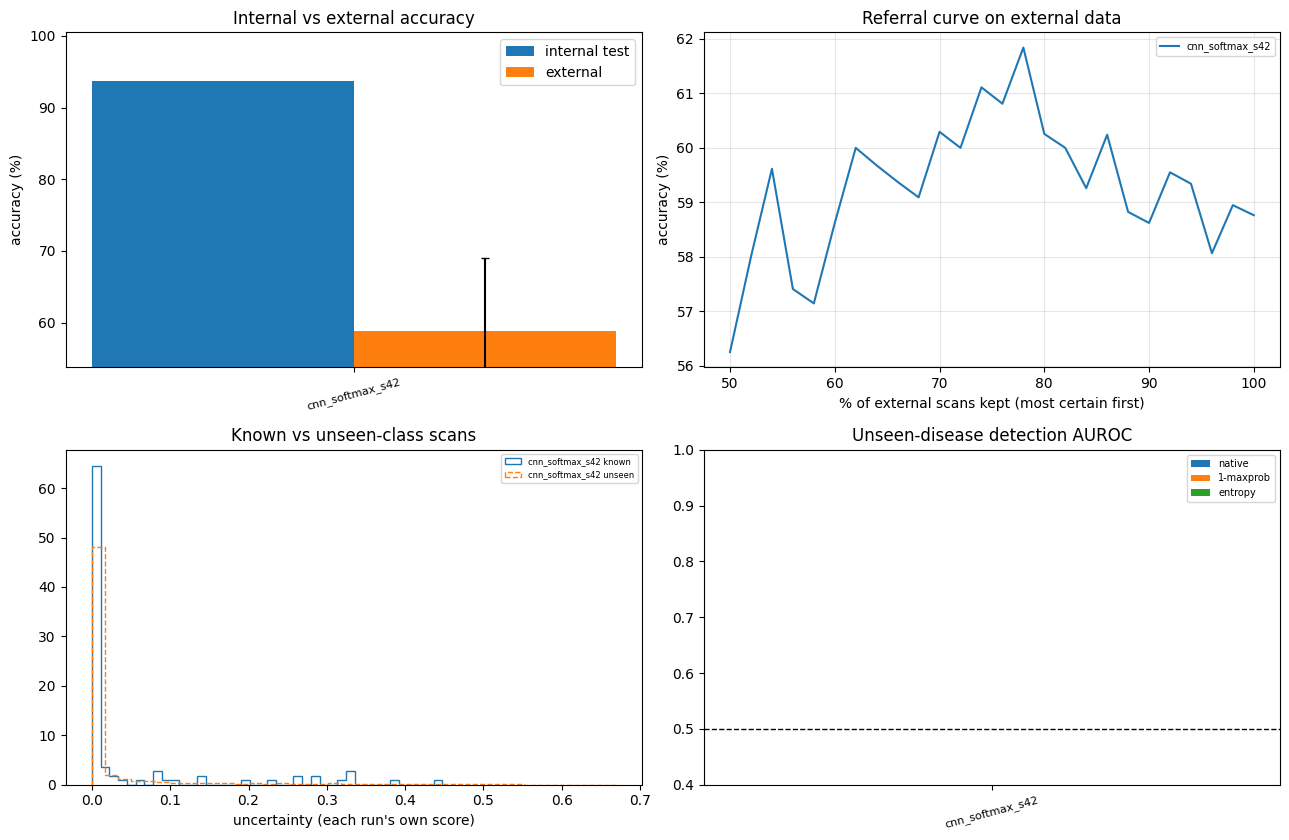

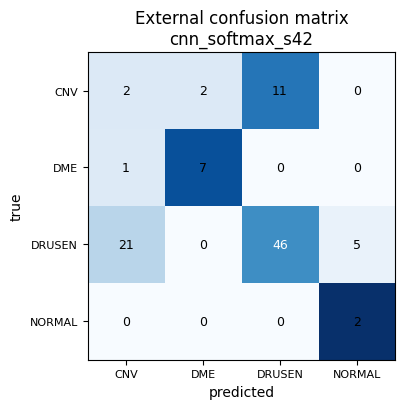

In [18]:
names = list(PRED)
fig, axs = plt.subplots(2, 2, figsize=(13, 8.5))

x = np.arange(len(names))
axs[0, 0].bar(x - 0.2, [ID_RES[n]["internal_acc"] * 100 for n in names], 0.4, label="internal test", color="tab:blue")
axs[0, 0].bar(x + 0.2, [ID_RES[n]["acc"] * 100 for n in names], 0.4, label="external", color="tab:orange",
              yerr=[[(ID_RES[n]["acc"] - ID_RES[n]["acc_ci"][0]) * 100 for n in names], [(ID_RES[n]["acc_ci"][1] - ID_RES[n]["acc"]) * 100 for n in names]], capsize=3)
axs[0, 0].set_xticks(x); axs[0, 0].set_xticklabels(names, rotation=15, fontsize=8)
axs[0, 0].set_ylim(max(0, min(min(ID_RES[n]["acc"] for n in names), min(ID_RES[n]["internal_acc"] for n in names)) * 100 - 5), 100.5)
axs[0, 0].set_ylabel("accuracy (%)"); axs[0, 0].set_title("Internal vs external accuracy"); axs[0, 0].legend()

cov = np.linspace(0.5, 1.0, 26)
for n in names:
    p = PRED[n]["probs"][id_mask]
    axs[0, 1].plot(cov * 100, [acc_at_coverage(y_id, p.argmax(1), PRED[n]["unc"][id_mask], c) * 100 for c in cov], label=n)
axs[0, 1].set_xlabel("% of external scans kept (most certain first)"); axs[0, 1].set_ylabel("accuracy (%)")
axs[0, 1].set_title("Referral curve on external data"); axs[0, 1].grid(alpha=0.3); axs[0, 1].legend(fontsize=7)

if OOD_RES:
    for n in names:
        axs[1, 0].hist(PRED[n]["unc"][id_mask], bins=40, histtype="step", density=True, label=f"{n} known")
        axs[1, 0].hist(PRED[n]["unc"][ood_mask], bins=40, histtype="step", density=True, linestyle="--", label=f"{n} unseen")
    axs[1, 0].set_xlabel("uncertainty (each run's own score)"); axs[1, 0].set_title("Known vs unseen-class scans"); axs[1, 0].legend(fontsize=6)

    wd = 0.25
    for k, sname in enumerate(("native", "1-maxprob", "entropy")):
        axs[1, 1].bar(x + (k - 1) * wd, [OOD_RES[n][sname]["auroc"] for n in names], wd, label=sname)
    axs[1, 1].axhline(0.5, color="k", ls="--", lw=1); axs[1, 1].set_ylim(0.4, 1.0)
    axs[1, 1].set_xticks(x); axs[1, 1].set_xticklabels(names, rotation=15, fontsize=8)
    axs[1, 1].set_title("Unseen-disease detection AUROC"); axs[1, 1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "external_plots.png", dpi=150); plt.show()

best = max(ID_RES, key=lambda n: ID_RES[n]["macro_f1"])
cm = np.array(ID_RES[best]["cm"])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, fontsize=8); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"External confusion matrix\n{best}")
plt.tight_layout(); plt.savefig(OUT_DIR / "external_confusion.png", dpi=150); plt.show()

## 10. Save and summary

In [19]:
json.dump({"external_root": str(EXT_ROOT), "files": len(E), "overlap_removed": int(n_ov), "evaluated": int(len(kept)),
           "in_distribution": int(id_mask.sum()), "unseen": int(ood_mask.sum()), "id_results": ID_RES, "ood_results": OOD_RES},
          open(OUT_DIR / "external_results.json", "w"), indent=2)

print(f"External set: {len(E):,} files, {n_ov:,} removed for overlap with our data, {len(kept):,} evaluated.\n")
for n, r in ID_RES.items():
    print(f"{n}: external accuracy {r['acc'] * 100:.2f}% (internal {r['internal_acc'] * 100:.2f}%, change {(r['acc'] - r['internal_acc']) * 100:+.2f} pp), macro-F1 {r['macro_f1']:.4f}")
if OOD_RES:
    print()
    for n, res in OOD_RES.items():
        print(f"{n}: unseen-disease detection AUROC {res['native']['auroc']:.3f} with its own uncertainty score "
              f"(1-max-prob {res['1-maxprob']['auroc']:.3f}, entropy {res['entropy']['auroc']:.3f})")
    print("\nIf evidential runs do not beat their softmax counterparts here, the evidential head adds nothing - say so in the paper.")
print("\nSaved in", OUT_DIR.resolve())

External set: 24,000 files, 11,903 removed for overlap with our data, 12,097 evaluated.

cnn_softmax_s42: external accuracy 58.76% (internal 93.69%, change -34.93 pp), macro-F1 0.5209

cnn_softmax_s42: unseen-disease detection AUROC 0.314 with its own uncertainty score (1-max-prob 0.314, entropy 0.316)

If evidential runs do not beat their softmax counterparts here, the evidential head adds nothing - say so in the paper.

Saved in C:\Users\User\Desktop\NNDL-2\outputs\external


## What to do next
- **Report the overlap table** (section 2) in the paper: it documents how independent the external set really is.
- A large accuracy drop on external data is a legitimate finding (scanner/site shift). Options to improve: stronger augmentation, or fine-tuning on a small part of the external data and reporting results on the rest.
- If unseen-disease AUROC is near 0.5 for every score, the uncertainty is not a safety feature on this data; do not claim it is.
- Next: **notebook 06** collects the tables and figures from notebooks 03-05 into paper-ready files.